# 02 · Feature Building

**Goal:** pair every entry with every matter it could belong to, and describe each pair with clues a rule or model can use to pick the right one.

**Output:** the pairs table, one row per (entry, candidate matter): 4,000 entries × 103 matters = 412,000 rows. For one entry it looks like this:

| entry | candidate matter | typed CMID is this matter? | client score | key term found? | task cue fits? | open on work date? | billed recently? | right answer? |
|---|---|---|---|---|---|---|---|---|
| T-00017 | 6103.004 2026 Annual Meeting | no | 100 | no | yes | yes | yes | **yes** |
| T-00017 | 6103.001 SEC Reporting | no | 100 | no | yes | yes | no | no |
| T-00017 | 9028.001 General Corporate | no | 39 | no | no | yes | no | no |

A second, smaller table has one row per piece of work in each narrative. It's only used to suggest how to divide entries that cover two matters.

**Kinds of clues**

| Kind | What it checks |
|---|---|
| Typed fields | the cleaned CMID, and fuzzy scores for the typed client and matter (notebook 01) |
| Narrative | words from each matter's name, task cues for the type of work, client names |
| Dates | whether the matter was open on the work date |
| Timekeeper history | whether this person billed the matter recently |
| Past narratives | how much the narrative reads like past entries on each matter |
| People | whether people named in the narrative were billed with this client before |

**Questions**
1. Do the cleanup steps recover the right values?
2. Which clues point to the right matter, and which only narrow things down?
3. Do the narrative clues hold up on VAL?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz import fuzz
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
from clean import normalize, is_ditto, clean_cmid, clean_entries, cmid_similarity
from fuzzy import client_name_table, matter_name_table, match, add_name_scores
from cues import cue_table, check_cue_types, CUE_SOURCES
from features import (make_pairs, add_cmid_features, keyterm_table, client_mention_table, window_score,
                      phrase_scores, add_text_features, add_date_features, add_history_features,
                      add_past_narrative_sim, not_people, known_people, find_people, person_history,
                      add_person_features, narrative_parts, match_parts, add_gaps, feature_groups, build_pairs)
from train import build_training_pairs

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
SHORTHAND_PATH = Path("../data/shorthand_bank.csv")   # billing shorthand, never read as client initials
TUNE, CHECK = "TRAIN", "VAL"

ENTRY_COLS = {"Time ID": "entry_id", "TK ID": "tk_id", "Source Format": "source_format", "Date": "work_date",
              "CMID": "cmid", "Client": "client", "Matter": "matter", "Narrative": "narrative"}
MATTER_COLS = {"CMID": "cmid", "Client": "client", "Matter": "matter", "Matter Type": "matter_type",
               "Status": "status", "Open Date": "open_date", "Close Date": "close_date"}
HISTORY_COLS = {"TK ID": "tk_id", "CMID": "cmid", "Hours (04/01-06/30/2026)": "hours"}
HISTORY_END = pd.Timestamp("2026-06-30")

PHRASE_MIN = 90   # a phrase counts as found in the narrative at this score or higher (section 7)

SEED = 210
FOLDS = 5
EMBEDDING_MODEL = "all-MiniLM-L6-v2"
PAST_K = 3   # past narratives averaged per matter (section 10)

## 2. Load data

- **Entries** come from notebook 00, so emails already have their fields filled in.
- **The answer key** (`KEY:` columns) is split off right away and only comes back at the end as labels, so the clues only use what a firm would actually have.
- **From Matter Master:** CMID, client, matter name, codename, aliases, matter type, status, and dates. Matter type and dates are standard in billing systems, so they're assumed to be available. The synthetic `Key Terms` and contact columns aren't used, since a firm's matter list wouldn't have them.

In [3]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None, dtype=str)
raw, matter_master = sheets["Time Entries"], sheets["Matter Master"]

entries = pd.read_parquet(RESULTS_DIR / "00_entries.parquet")[list(ENTRY_COLS.values())]
matters = matter_master[list(MATTER_COLS)].rename(columns=MATTER_COLS)
history = sheets["TK Matter History"][list(HISTORY_COLS)].rename(columns=HISTORY_COLS)
answers = (raw[["Time ID"] + [c for c in raw.columns if c.startswith("KEY: ")]]
           .rename(columns=lambda c: "entry_id" if c == "Time ID" else c.replace("KEY: ", "key_").lower().replace(" ", "_"))
           .rename(columns={"key_split": "split"}))
valid_cmids = set(matters["cmid"])
acronym_skip = pd.read_csv(SHORTHAND_PATH)["shorthand"].tolist()

assert entries["entry_id"].tolist() == raw["Time ID"].tolist()
assert set(answers["split"]) == {"TRAIN", "VAL", "TEST"}
assert not any(c.startswith("KEY") for c in entries.columns)
assert pd.to_datetime(entries["work_date"]).min() > HISTORY_END
print(f"{len(entries):,} entries | {len(matters)} matters | {matters['matter_type'].nunique()} matter types")

4,000 entries | 103 matters | 18 matter types


## 3. Cleaning up the typed fields

Three fixes before matching:
- **Ditto marks:** handwritten sheets use `"`, "ditto", "same", or "↓" for "same client as above".
- **Client and matter in one field:** "Meridian / sec reporting", "Juniper Peak-Fund II".
- **CMIDs written in the narrative:** fill a blank CMID field.

In [4]:
fields = clean_entries(entries)
check = entries.join(fields).merge(answers[["entry_id", "split", "key_true_client", "key_true_cmid"]], on="entry_id")
train = check[check["split"] == TUNE].copy()
client_names = client_name_table(matter_master, acronym_skip)


def points_to(typed, true_client):
    top = match(typed, client_names, k=1) if isinstance(typed, str) and not is_ditto(typed) else []
    return bool(top) and top[0][0] == true_client


# Ditto: is the previous row by the same timekeeper the right client?
check["prev_client"] = check.groupby("tk_id")["client"].shift()
dittos = check[(check["split"] == TUNE) & check["client"].map(is_ditto)]
prev_right = np.mean([points_to(p, t) for p, t in zip(dittos["prev_client"], dittos["key_true_client"])])

# One field: does matching only the client part pick the true client more often?
one_field = train[train["client_had_matter"] == 1]
whole = np.mean([points_to(c, t) for c, t in zip(one_field["client"], one_field["key_true_client"])])
part = np.mean([points_to(c, t) for c, t in zip(one_field["typed_client"], one_field["key_true_client"])])

# CMID in the narrative
in_text = train[train["cmid_from_text"] == 1]

print(f"Ditto marks: {len(dittos)} | previous row by the same timekeeper has the true client: {prev_right:.0%}")
print(f"One-field clients: {len(one_field)} | true client from the whole field: {whole:.0%}, from the client part: {part:.0%}")
print(f"CMIDs found in narratives: {len(in_text)}")
one_field[["client", "typed_client", "typed_matter", "key_true_client"]].head()

Ditto marks: 19 | previous row by the same timekeeper has the true client: 21%
One-field clients: 52 | true client from the whole field: 92%, from the client part: 98%
CMIDs found in narratives: 0


,client,typed_client,typed_matter,key_true_client
15,Maridian Therapevtics-sec,Maridian Therapevtics,sec,Meridian Therapeutics
19,Meridian / sec reporting,Meridian,sec reporting,Meridian Therapeutics
262,Northgate Capital Partners / Acq of Summit Ridge,Northgate Capital Partners,Acq of Summit Ridge,Northgate Capital Partners
294,Meridian Tx / sec reporting,Meridian Tx,sec reporting,Meridian Therapeutics
406,Northgate – Asterion,Northgate,Asterion,Northgate Bank


- **Ditto marks are treated as a blank client.** The row above usually isn't the line above on the paper sheet, so it only has the true client about 1 time in 5.
- **One-field clients are split at the first "/" or "-".** No client name contains one, and the client part picks the true client 98% of the time (92% for the whole field). The right-hand part becomes the typed matter.
- **CMIDs in the narrative don't come up on TRAIN,** since formats with a CMID field use it and emails already have theirs.

## 4. The pairs table

Every entry is paired with every matter, so the right matter is always one of the candidates. Each section below adds columns.

In [5]:
pairs = make_pairs(entries, matters)
print(f"{len(entries):,} entries x {len(matters)} matters = {len(pairs):,} pairs")

4,000 entries x 103 matters = 412,000 pairs


## 5. CMID

Typed CMIDs have three kinds of problems:

| Problem | Example | Fix |
|---|---|---|
| Format | `3012004`, `3012/004`, `3012.4` | a pattern |
| OCR letters | `61D3.004`, `6103.O05` | read letters as the digits they look like |
| Doesn't exist | not in Matter Master | either a typo of a real CMID or a matter that isn't open yet |

In [6]:
pairs = add_cmid_features(pairs, valid_cmids)

per_entry = pairs.drop_duplicates("entry_id").merge(answers, on="entry_id")
ocr_fixed = per_entry["cmid_clean"].notna() & ~per_entry["typed_cmid"].fillna("").str.fullmatch(r"[\d\s.\-/,]*")
print("Entries by CMID status:", per_entry["cmid_status"].value_counts().to_dict())
print("Fixed by reading OCR letters as digits:", ocr_fixed.sum())
per_entry.loc[ocr_fixed, ["typed_cmid", "cmid_clean"]].head(6)

Entries by CMID status: {'missing': 2029, 'valid': 1408, 'reformatted': 391, 'invalid': 172}
Fixed by reading OCR letters as digits: 131


,typed_cmid,cmid_clean
12,bID3 o04,6103.004
46,"3|Z0,O0I",3120.001
70,72ZZ.00Z,7222.002
86,61D3.004,6103.004
87,6103.O05,6103.005
129,34Ss.D02,3455.002


In [7]:
bad = per_entry[(per_entry["cmid_status"] == "invalid") & (per_entry["split"] == TUNE)].copy()
bad["client_number_exists"] = bad["cmid_client_known"] == 1
bad["closest"] = bad["cmid_flipped"].fillna(bad["cmid_clean"].map(lambda c: max(valid_cmids, key=lambda v: (cmid_similarity(c, v), v))))
bad["closest_is_true"] = bad["closest"] == bad["key_true_cmid"]
bad.groupby(["key_expected_action", "client_number_exists"]).agg(entries=("entry_id", "size"), closest_is_true=("closest_is_true", "mean")).round(2)

entries  closest_is_true
key_expected_action client_number_exists                          
AUTO_MATCH          False                       9             1.00
                    True                       52             0.63
NO_MATCH            False                      27             0.00
                    True                       30             0.00

- **The OCR step fixes all 131 CMIDs with letters in them.**
- **Typos** (expected `AUTO_MATCH`): the closest real CMID is the true matter about 70% of the time.
- **Not open yet** (expected `NO_MATCH`): about half have a real client number (`9140.009`, a new matter at a known client), so the CMID alone can't tell them from typos. The other clues have to decide.

## 6. Names

Fuzzy scores for the typed client against each candidate's client, and the typed matter against each candidate's matter name or codename (0 when blank). Notebook 01's picks are used, plus their runner-ups.

In [8]:
choice = json.loads((RESULTS_DIR / "01_scorer_choice.json").read_text())
SCORERS = list(dict.fromkeys([choice["client_scorer"], choice["matter_scorer"], choice["client_runner_up"], choice["matter_runner_up"]]))
CLIENT_COL, MATTER_COL = f"client_{choice['client_scorer'].lower()}", f"matter_{choice['matter_scorer'].lower()}"

matter_names = matter_name_table(matter_master)
pairs = add_name_scores(pairs, client_names, matter_names, SCORERS)
print("Scorers:", SCORERS)

Scorers: ['ratio', 'token_sort_ratio', 'token_set_ratio']


## 7. Narrative

The narrative is the one field that's always filled in. Three kinds of phrases are searched for:
- **Key terms** from each matter's name and codename. Generic words are trimmed ("Acquisition of Brightline Pumps" gives "brightline"), and all-generic names ("General Corporate") give none. A term shared by several matters ("fund ii") only narrows things down.
- **Task cues** that hint at the type of work ("capital call" means fund administration), from public lists: UTBMS billing task codes, SEC form names, standard deal documents, and NALP recruiting terms.
- **Client names,** aliases, and initials. Initials are built from each client name ("Northgate Capital Partners" gives "NCP") and only count when written exactly, in capitals. Initials under three letters, shared by two clients, or in the billing shorthand list (`data/shorthand_bank.csv`, like "SPA") are left out, since they'd match the wrong thing.

Phrases are matched against whole words, so "tern" doesn't match inside "internal" but typos still score high. Numbers, roman numerals, and single letters have to match exactly, since Fund II and Fund III are different matters.

In [9]:
demo = [("tern", "draft internal memo"), ("capital call", "prep capial call notices"),
        ("fund ii", "track fund iii investor subscriptions"), ("450 harbor", "review title commitment for 450 harbour st")]
pd.DataFrame([{"phrase": p, "narrative": t, "partial_ratio": round(fuzz.partial_ratio(p, t)),
               "window_score": round(window_score(p, t))} for p, t in demo])

,phrase,narrative,partial_ratio,window_score
0,tern,draft internal memo,100,67
1,capital call,prep capial call notices,92,96
2,fund ii,track fund iii investor subscriptions,100,0
3,450 harbor,review title commitment for 450 harbour st,90,95


In [10]:
keyterms = keyterm_table(matter_master)
cues = cue_table()
client_mentions = client_mention_table(matter_master, acronym_skip=acronym_skip)
check_cue_types(cues, matters["matter_type"])

print(f"Key terms: {len(keyterms)} for {keyterms['cmid'].nunique()} matters ({keyterms['shared'].sum()} shared by 2+ matters)")
print(f"Task cues: {cues['cue_norm'].nunique()} for {cues['matter_type'].nunique()} matter types")
print(f"Client names and aliases: {(client_mentions['kind'] == 'name').sum()} | initials: {(client_mentions['kind'] == 'acronym').sum()} "
      f"({', '.join(client_mentions.loc[client_mentions['kind'] == 'acronym', 'name'])})")
cues.drop_duplicates("cue_norm")["source"].value_counts().rename("cues").to_frame().assign(source=lambda d: d.index.map(CUE_SOURCES))

Key terms: 153 for 73 matters (54 shared by 2+ matters)
Task cues: 205 for 18 matter types
Client names and aliases: 107 | initials: 7 (CRP, MTS, EGE, NCP, OLH, PBH, LSG)


,cues,source
source,,
DOCS,96,Standard transaction document names
UTBMS_MA,45,ABA/LOC Mergers & Acquisitions UTBMS code set ...
FIRM,25,Common law-firm internal work and wording (to ...
SEC,19,SEC form and filing names (EDGAR)
NVCA,13,NVCA model venture capital financing documents
NALP,7,NALP (National Association for Law Placement) ...


### Choosing the cutoff

Every key term and cue is scored against every TRAIN narrative. A match is **right** if the phrase belongs to the entry's true matter (key terms) or its matter type (cues).

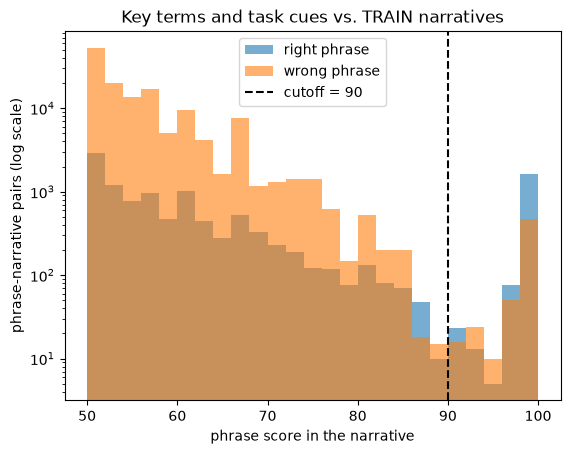

In [11]:
type_of = matters.set_index("cmid")["matter_type"]
labeled = train[train["key_true_cmid"] != "NONE"]
true_cmid = dict(zip(labeled["narrative"].map(lambda t: normalize(t, drop_suffixes=False)), labeled["key_true_cmid"]))
scores = phrase_scores(list(keyterms["term_norm"]) + list(cues["cue_norm"]), true_cmid.keys())

long = scores.stack().rename("score").reset_index().set_axis(["text", "phrase", "score"], axis=1).query("score >= 50")
long["true_cmid"] = long["text"].map(true_cmid)
term_owner = keyterms.groupby("term_norm")["cmid"].agg(set)
cue_types = cues.groupby("cue_norm")["matter_type"].agg(set)
long["right"] = [c in term_owner.get(p, set()) or type_of[c] in cue_types.get(p, set()) for p, c in zip(long["phrase"], long["true_cmid"])]

bins = np.linspace(50, 100, 26)
plt.hist(long.loc[long["right"], "score"], bins=bins, alpha=0.6, label="right phrase")
plt.hist(long.loc[~long["right"], "score"], bins=bins, alpha=0.6, label="wrong phrase")
plt.axvline(PHRASE_MIN, color="black", linestyle="--", label=f"cutoff = {PHRASE_MIN}")
plt.yscale("log")
plt.xlabel("phrase score in the narrative")
plt.ylabel("phrase-narrative pairs (log scale)")
plt.title("Key terms and task cues vs. TRAIN narratives")
plt.legend()
plt.show()

- **The cutoff stays at 90.** Right matches cluster at 100, typos of real phrases ("capial call") land between 90 and 99, and look-alikes ("nda" vs. "snda") fall below 90.
- **Some wrong matches score 100:** the word is really there but means other work, like "closing" in "in preparation for closing". No cutoff fixes those, so the model has to weigh cues against the other clues.

In [12]:
pairs = add_text_features(pairs, keyterms, cues, client_mentions, PHRASE_MIN)

## 8. Dates and timekeeper history

- **Dates:** time can't be billed to a matter before it opened or after it closed.
- **History:** hours each timekeeper billed to each matter from April 1 to June 30, 2026. Every entry is dated after that, so history never includes the entries it's used to predict. Matters opened after June can't have history yet, which `opened_after_history` marks.

In [13]:
pairs = add_date_features(pairs, HISTORY_END)
pairs = add_history_features(pairs, history)

typed_rows = pairs[pairs["is_typed_cmid"] == 1].merge(answers, on="entry_id").query("split == @TUNE")
typed_rows.groupby("key_entry_category")["not_open"].mean().round(2).rename("typed matter not open").to_frame()

,typed matter not open
key_entry_category,
CLEAN,0.0
CLOSED_OR_NOT_OPEN,1.0
MESSY,0.0
SPLIT_NAMED,0.0
SPLIT_UNNAMED,0.0
WRONG_CMID_SILENT,0.0
WRONG_CMID_TEXT,0.0


- **`not_open` is a clean signal:** only `CLOSED_OR_NOT_OPEN` entries have a typed matter that wasn't open on the work date.

## 9. Put it together

`build_pairs` in `src/features.py` runs every step above in one call, which is what notebook 03 and the app use. The check makes sure it matches the step-by-step table.

Each `_gap` column is a candidate's value minus the best value in its entry (0 = tied for best), so a model can compare candidates within an entry.

In [14]:
GAP_COLS = [CLIENT_COL, MATTER_COL, "keyterm_score", "cue_share", "client_in_text", "history_share", "cmid_similarity"]
pairs = add_gaps(pairs, GAP_COLS).sort_values(["entry_id", "cmid"]).reset_index(drop=True)

rebuilt = build_pairs(entries, matters, history, client_names, matter_names, keyterms, cues, client_mentions,
                      SCORERS, PHRASE_MIN, GAP_COLS, HISTORY_END)
pd.testing.assert_frame_equal(rebuilt, pairs)

FEATURES = feature_groups(SCORERS, GAP_COLS)
FEATURE_COLS = [c for cols in FEATURES.values() for c in cols]
print(f"{len(FEATURE_COLS)} features:", {group: len(cols) for group, cols in FEATURES.items()})

44 features: {'typed_fields': 9, 'cmid': 6, 'names': 6, 'narrative': 10, 'dates': 2, 'history': 4, 'gaps': 7}


### Labels

A candidate is a true matter if it's the entry's True CMID or Secondary CMID (the second matter when an entry covers two). `NO_MATCH` entries have no true matter.

In [15]:
pairs = pairs.merge(answers, on="entry_id", how="left")
pairs["is_true_matter"] = [int(c in (t, s)) for c, t, s in zip(pairs["cmid"], pairs["key_true_cmid"], pairs["key_secondary_cmid"])]

expected = pairs.groupby("entry_id")["key_expected_action"].first().map({"SPLIT_ENTRY": 2, "NO_MATCH": 0}).fillna(1)
assert (pairs.groupby("entry_id")["is_true_matter"].sum() == expected).all()
print(f"{len(pairs):,} pairs | {pairs['is_true_matter'].sum():,} true matters")

412,000 pairs | 4,001 true matters


## 10. Past narratives (billing history)

Key terms only cover words in matter names. Lawyers also write counterparties, investors, and deal shorthand ("call w/ Arcadia re SPA") that no matter list has, but a firm's **billing history** does.

- **Sentence embeddings** (`all-MiniLM-L6-v2`) turn each narrative into a list of numbers that captures its meaning, so narratives about the same work land close together even when the wording differs.
- **`past_narrative_sim`** is how closely an entry reads like past entries on each candidate matter (average of the 3 closest, by cosine similarity).
- **No peeking:** TRAIN entries stand in for billing history. TRAIN is split into 5 folds, and a TRAIN entry is only compared with the other folds, never itself. VAL and TEST are compared with all of TRAIN, the way new entries would be compared with past ones. Notebook 04 cross-validates on the same folds.

The first run downloads the embedding model (about 90 MB).

In [16]:
train_ids = answers.loc[answers["split"] == "TRAIN", "entry_id"].sample(frac=1, random_state=SEED)
folds = dict(zip(train_ids, np.arange(len(train_ids)) % FOLDS))

entry_text = pairs.drop_duplicates("entry_id")[["entry_id", "split", "key_true_cmid", "narrative_norm"]].reset_index(drop=True)
encoder = SentenceTransformer(EMBEDDING_MODEL)
vecs = encoder.encode(entry_text["narrative_norm"].tolist(), normalize_embeddings=True)

pairs = add_gaps(add_past_narrative_sim(pairs, entry_text, vecs, folds, k=PAST_K), ["past_narrative_sim"])
pairs["fold"] = pairs["entry_id"].map(folds).fillna(-1).astype(int)
FEATURES["past_narratives"] = ["past_narrative_sim", "past_narrative_sim_gap"]
FEATURE_COLS += FEATURES["past_narratives"]

pairs[pairs["split"] == "VAL"].groupby("is_true_matter")["past_narrative_sim"].describe().round(2)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
is_true_matter,,,,,,,,
0,61302.0,0.27,0.17,0.0,0.16,0.29,0.39,1.0
1,601.0,0.61,0.18,0.0,0.52,0.61,0.70,1.0


- **The clue carries real signal:** on VAL, the right matter averages 0.61 similarity to its past narratives vs. 0.27 for other candidates.
- **It picks up what the matter list can't:** counterparties, investors, and shorthand people actually write.

## 11. People named in the narrative (billing history)

Narratives often name who the work was with ("tcw S. Bauer", "call w/ Kaur re closing"). People usually belong to one client, so a known name hints at the client, and a name billed with a *different* client is a warning sign: a wrong CMID, or a second matter in the same entry.

| Step | How |
|---|---|
| Who counts (`known_people`) | an initial and surname ("M. Carter" → "m carter"), or a capitalized word right after "w/" or "with" ("Kaur"), in a TRAIN narrative. Role words ("Client") and words from client and matter names are skipped. |
| Finding them (`find_people`) | a known initial and surname, or a known surname right after "w"/"with". Case and punctuation don't matter, and the initial has to be one seen with that surname, so "a grant of options" isn't read as O. Grant. |
| History (`person_history`) | which client each person was billed with, from TRAIN entries with one known matter. Like past narratives, a TRAIN entry only uses the other folds. |

The list comes from billing history, not Matter Master, since a firm's matter list doesn't track contacts.
- `person_hits`: people named who were billed with this candidate's client before
- `person_conflict`: people named who were billed before, but never with this candidate's client

In [17]:
skip = not_people(matter_master)
PEOPLE = known_people(entries.loc[entries["entry_id"].isin(train_ids), "narrative"], skip)
named = find_people(entry_text.set_index("entry_id")["narrative_norm"], PEOPLE)
person_hist = person_history(answers, named, matters, folds)

pairs = add_person_features(pairs, named, person_hist, folds)
FEATURES["people"] = ["person_hits", "person_conflict"]
FEATURE_COLS += FEATURES["people"]

print(f"{len(PEOPLE)} people in billing history | {(named.str.len() > 0).mean():.0%} of entries name at least one")
print(", ".join(PEOPLE))
pairs[pairs["split"].isin([TUNE, CHECK])].groupby(["split", "is_true_matter"])[["person_hits", "person_conflict"]].apply(
    lambda d: (d > 0).mean()).round(3)

67 people in billing history | 20% of entries name at least one
a rivera, a stone, a wu, b lyle, banks, black, c abbott, c morgan, c ward, d chu, d ferin, d park, dubois, e lindqvist, e ruiz, f dubois, f kerr, g hollis, grant, h ford, h quan, hayes, j black, j lee, j mercer, j ortiz, k lowe, k moss, k osei, kaur, lee, lindqvist, m carter, m carterre, m cruz, m reyes, mendez, n shah, o grant, o pratt, ocboa, ochoa, p ames, p liu, p liv, p nair, r dale, r iyer, r vance, s bauer, s cole, s ng, s patil, shah, t okada, t smitb, t smith, t walsh, v kaur, v lund, vance, w hale, w hole, w ochoa, y abe, y tanaka, z kemp


person_hits  person_conflict
split is_true_matter                              
TRAIN 0                     0.006            0.191
      1                     0.197            0.013
VAL   0                     0.007            0.190
      1                     0.193            0.015

- **The list is clean:** almost every name is a real person, and the few extras are OCR misspellings of real names ("Ocboa", "Smitb").
- **About 1 in 5 entries names someone billing history knows.** When one does, the right matter's client is almost always a hit, while other candidates almost never are (under 1%).
- **Conflicts on the right matter are rare (about 1.5%)** vs. about 1 in 5 other candidates. Most of those are multi-matter entries where the person belongs to the second matter, which is exactly what step 2 should notice.
- **People narrow rather than decide:** like a typed client, a person points to a client, not one matter.

### Checking the people list

Two checks before the clue is used:
- **Examples:** a few phrasings that should and shouldn't count as a person.
- **Contact lists:** Matter Master's `Client Contacts` and `Matter Contacts` columns aren't used to build anything, since a firm's matter list wouldn't have them. Here they work as an answer key: how many listed surnames are real contacts, and how many entries that name a contact get a person found.

In [18]:
examples = {"tcw S. Bauer re SPA": ["bauer"], "CALL WITH S. NG RE LP AGREEMENT": ["ng"], "call w/ Kaur re closing": ["kaur"],
            "revise option grant notices": [], "a grant of options to the CEO": [], "Draft SPA. Review title": []}
found = find_people(pd.Series(list(examples)).map(lambda t: normalize(t, drop_suffixes=False)), PEOPLE)
assert found.tolist() == list(examples.values()), found.tolist()

contacts = sorted({normalize(p) for col in ["Client Contacts", "Matter Contacts"] for v in matter_master[col].dropna() for p in v.split(",")})
contact_surnames = {c.split()[-1] for c in contacts}
listed = {p.split()[-1] for p in PEOPLE}
names_contact = find_people(entry_text.set_index("entry_id")["narrative_norm"], contacts).str.len() > 0
person_found = named.str.len() > 0
print(f"Surnames in the list: {len(listed)} | real contacts: {len(listed & contact_surnames)} | others: {', '.join(sorted(listed - contact_surnames))}")
print(f"Entries naming a contact the usual way: {names_contact.sum():,} | with a person found: {person_found[names_contact].mean():.0%} | "
      f"person found but no contact named: {(person_found & ~names_contact).sum()}")

Surnames in the list: 58 | real contacts: 52 | others: carterre, ferin, hole, liv, ocboa, smitb
Entries naming a contact the usual way: 781 | with a person found: 100% | person found but no contact named: 5


- **The examples behave:** initials and "with" find the person in any case, and "option grant" or "a grant of options" don't.
- **52 of 58 surnames are real contacts.** The other 6 are OCR misspellings of real names, so they still point to the right client.
- **Every entry that names a contact the usual way gets a person found** (781 entries). Only 5 entries get a person who isn't a contact, all from those misspellings.

## 12. Narrative parts

A narrative often lists several pieces of work ("Draft SPA (1.1); call w/ client (.3)"). `split_parts` cuts it at semicolons, hours in parentheses, sentence ends, and linking words like "also" and "plus", and `n_parts` counts the pieces.

When an entry covers two matters, someone has to divide it, so each part is also matched on its own (`match_parts`):
- **named_cmid:** a matter the part names by one of its own key terms
- **top_cmids:** the part's three most similar matters by past narratives

These go in a separate parts table and are only used to suggest a split (notebook 04), not as clues.

In [19]:
parts = narrative_parts(entries.set_index("entry_id").loc[entry_text["entry_id"]].reset_index())
part_vecs = encoder.encode(parts["part_norm"].tolist(), normalize_embeddings=True)
parts = match_parts(parts, part_vecs, entry_text, vecs, folds, matters["cmid"].unique(), keyterms, PHRASE_MIN, k=PAST_K)
print(f"{len(parts):,} parts from {parts['entry_id'].nunique():,} entries")

example = answers.query("split == @TUNE and key_entry_category == 'SPLIT_NAMED'")["entry_id"].iloc[1]
print(entries.set_index("entry_id").loc[example, "narrative"], "| true:", answers.set_index("entry_id").loc[example, ["key_true_cmid", "key_secondary_cmid"]].tolist())
parts.query("entry_id == @example")[["part_norm", "named_cmid", "top_cmids", "top_sims"]]

7,036 parts from 4,000 entries
Attend to good standing requests; update closing checklist (1.1); attend to third-party consents tra- cker for Fieldstone (.6) | true: ['3120.001', '5531.001']


,part_norm,named_cmid,top_cmids,top_sims
202,attend to good standing requests,NaN,3120.001 | 8347.001 | 6110.001,0.83 | 0.49 | 0.41
203,update closing checklist,NaN,3120.001 | 9140.001 | 2960.001,0.69 | 0.64 | 0.60
204,attend to third party consents tra cker for fi...,5531.001,9140.001 | 3455.002 | 2960.001,0.44 | 0.42 | 0.41


In [20]:
multi = answers.query("split == @TUNE and key_secondary_cmid.notna()")[["entry_id", "key_entry_category", "key_secondary_cmid"]]
found = parts.merge(multi, on="entry_id")
found["names_second"] = found["named_cmid"] == found["key_secondary_cmid"]
found["second_most_similar"] = found["top_cmids"].str.split(" | ", regex=False).str[0] == found["key_secondary_cmid"]
found.groupby(["key_entry_category", "entry_id"])[["names_second", "second_most_similar"]].any().groupby(level=0).mean().round(2).rename(index=lambda c: c.replace("SPLIT", "MULTI"))

,names_second,second_most_similar
key_entry_category,,
MULTI_NAMED,0.23,0.18
MULTI_UNNAMED,0.00,0.04


- **The split finds the real tasks:** 7,036 parts from 4,000 entries. In the example, the first two parts read most like past entries on 3120.001 and the third names Fieldstone's matter (5531.001), the entry's two true matters.
- **Parts only help when the narrative hints at the second matter.** For named multi-matter entries, a part names the second matter about 1 time in 4 and reads most like it about 1 time in 6. For unnamed ones it almost never does.
- **So parts can suggest a split, but can't find a second matter that isn't described.** Spotting those entries is left to the classifier in notebook 04.

## 13. Which clues point to the right matter? (TRAIN)

For each entry, a clue "points to" the candidate(s) with its highest value. Only entries with one matter are counted.
- **speaks:** share of entries where the clue points anywhere
- **right alone:** when it speaks, share where it points only to the true matter

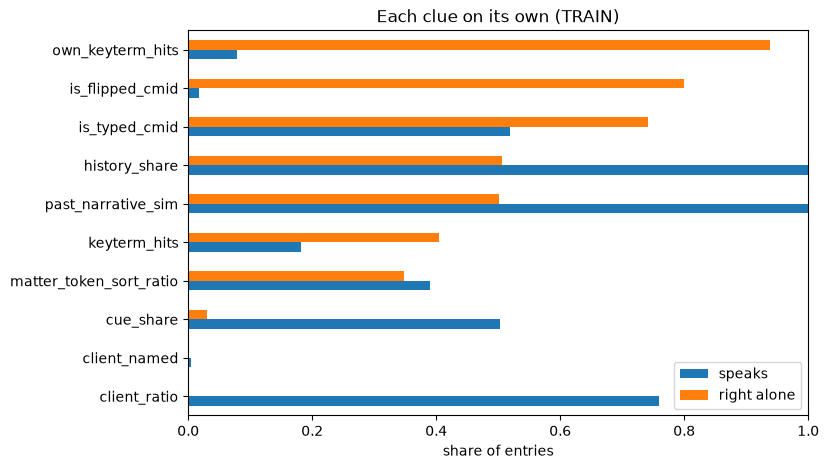

,speaks,right alone
is_typed_cmid,0.52,0.74
own_keyterm_hits,0.08,0.94
is_flipped_cmid,0.02,0.80
keyterm_hits,0.18,0.41
matter_token_sort_ratio,0.39,0.35
history_share,1.00,0.51
cue_share,0.50,0.03
client_ratio,0.76,0.00
client_named,0.00,0.00
past_narrative_sim,1.00,0.50


In [21]:
def clue_check(df, clues):
    rows = {}
    for clue in clues:
        best = df.groupby("entry_id")[clue].transform("max")
        points = (df[clue] == best) & (best > 0)
        n_points = points.groupby(df["entry_id"]).sum()
        hits_true = (points & (df["is_true_matter"] == 1)).groupby(df["entry_id"]).any()
        speaks = n_points > 0
        rows[clue] = {"speaks": speaks.mean(), "right alone": (hits_true & (n_points == 1))[speaks].mean()}
    return pd.DataFrame(rows).T


one_matter = pairs["key_expected_action"].isin(["AUTO_MATCH", "FLAG_MISMATCH"])
pairs["client_named"] = (pairs["client_in_text"] >= PHRASE_MIN).astype(int)
CLUES = ["is_typed_cmid", "own_keyterm_hits", "is_flipped_cmid", "keyterm_hits", MATTER_COL, "history_share",
         "cue_share", CLIENT_COL, "client_named", "past_narrative_sim"]

clues_train = clue_check(pairs[one_matter & (pairs["split"] == TUNE)], CLUES)
ax = clues_train.sort_values("right alone").plot.barh(figsize=(8, 5), xlim=(0, 1), title="Each clue on its own (TRAIN)")
ax.set_xlabel("share of entries")
plt.show()
clues_train.round(2)

- **The typed CMID** speaks on about half of entries and is right alone about three quarters of the time. Its misses are wrong CMIDs and multi-matter entries.
- **Key terms from a matter's own name** rarely speak (8%) but are right alone 94% of the time.
- **Past narratives and timekeeper history** always speak and each picks the right matter alone about half the time, which makes them the strongest tie-breakers.
- **Typed clients and task cues narrow but don't decide,** since they point to every matter of one client or one type.
- **No single clue is enough,** which is why notebook 03 combines them, starting from the client.

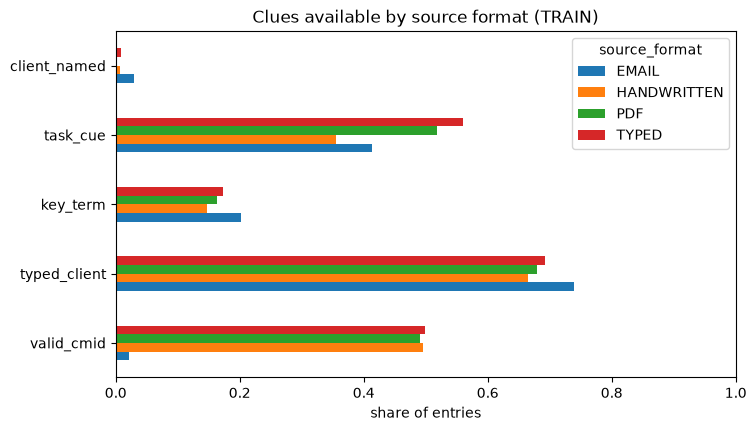

In [22]:
per_entry = pairs[pairs["split"] == TUNE].groupby("entry_id").agg(
    source_format=("source_format", "first"),
    valid_cmid=("cmid_valid", "max"),
    typed_client=(CLIENT_COL, lambda s: s.max() >= 80),
    key_term=("keyterm_hits", lambda s: s.max() > 0),
    task_cue=("cue_hits", lambda s: s.max() > 0),
    client_named=("client_named", "max"))

ax = per_entry.groupby("source_format").mean().T.plot.barh(figsize=(8, 4.5), xlim=(0, 1), title="Clues available by source format (TRAIN)")
ax.set_xlabel("share of entries")
plt.show()

- **Typed, PDF, and handwritten entries look alike:** about half have a valid CMID and two thirds a typed client.
- **Emails almost never have a valid CMID,** so the client, history, and narrative clues carry them.

## 14. Two cases left for the model

**Unnamed multi-matter entries:** the narrative mentions other work ("call re unrelated clsg") without naming the matter.

In [23]:
first_rows = pairs[pairs["split"] == TUNE].drop_duplicates("entry_id")
group = np.select([first_rows["key_entry_category"] == "SPLIT_UNNAMED", first_rows["key_entry_category"] == "SPLIT_NAMED"],
                  ["unnamed multi-matter", "named multi-matter"], "one matter")
first_rows.groupby(group).agg(entries=("entry_id", "size"),
                              names_a_matter=("n_matters_named", lambda s: (s >= 1).mean()),
                              two_plus_parts=("n_parts", lambda s: (s >= 2).mean()),
                              two_plus_types=("n_types_cued", lambda s: (s >= 2).mean())).round(2)

,entries,names_a_matter,two_plus_parts,two_plus_types
named multi-matter,77,0.27,0.99,0.57
one matter,2628,0.07,0.41,0.23
unnamed multi-matter,97,0.06,1.00,0.26


- **"Two parts means two matters" doesn't work.** Every unnamed multi-matter entry has two or more parts, but so do 41% of one-matter entries (mostly block billing), about 11 times as many. A rule would mostly flag one-matter entries, so these are left to the classifier.

**Acronyms:** clients typed as initials ("PRH", "NGB") that aren't listed aliases.

In [24]:
acronyms = first_rows[first_rows["key_client_surface"] == "UNLISTED_ACRONYM"]
print(f"{len(acronyms)} of {len(first_rows)} TRAIN entries ({len(acronyms) / len(first_rows):.1%})")

86 of 2802 TRAIN entries (3.1%)


- **Acronyms are about 3% of entries.** Three-letter initials that belong to one client are recognized (section 7). The rest collide ("HB" fits Harborlight Bio and Harborline Biosciences) or are too short to trust, so the narrative and past narratives have to carry them.

## 15. Check on VAL (once)

The cutoff was chosen on TRAIN, and VAL has phrasings TRAIN doesn't.

In [25]:
TEXT_CLUES = ["own_keyterm_hits", "keyterm_hits", "cue_share", "client_named", "past_narrative_sim"]
pd.concat({split: clue_check(pairs[one_matter & (pairs["split"] == split)], TEXT_CLUES) for split in [TUNE, CHECK]}, axis=1).round(2)

TRAIN                VAL            
                   speaks right alone speaks right alone
own_keyterm_hits     0.08        0.94   0.09        0.91
keyterm_hits         0.18        0.41   0.18        0.47
cue_share            0.50        0.03   0.55        0.02
client_named         0.00        0.00   0.00        0.00
past_narrative_sim   1.00        0.50   1.00        0.53

- **The narrative clues hold up on VAL:** key terms are right alone 94% on TRAIN and 91% on VAL, past narratives 50% and 53%, and coverage is about the same.

### The same steps in `src/train.py`

`build_training_pairs` in `src/train.py` runs this notebook's steps in one call, so the system can be retrained on a firm's own history without the notebook. The check makes sure it builds exactly this table, people list, and people history.

In [26]:
rebuilt, rebuilt_features, rebuilt_info = build_training_pairs(entries, answers, sheets, encoder, choice, acronym_skip, HISTORY_END)
check_cols = ["entry_id", "cmid", "fold"] + FEATURE_COLS + ["is_true_matter"]
pd.testing.assert_frame_equal(rebuilt[check_cols].reset_index(drop=True), pairs[check_cols].reset_index(drop=True))
assert rebuilt_features == FEATURES and rebuilt_info["people"] == PEOPLE
pd.testing.assert_frame_equal(rebuilt_info["person_hist"], person_hist)
print("build_training_pairs matches this notebook:", len(rebuilt), "pairs,", len(FEATURE_COLS), "clues")

build_training_pairs matches this notebook: 412000 pairs, 48 clues


## 16. Save

- `02_pairs.parquet`: the pairs table. Parquet is much smaller than a CSV at 400,000 rows and keeps column types, so CMIDs like `1111.010` stay text.
- `02_parts.parquet`: the parts table.
- `02_people.parquet`: the people history.
- `02_config.json`: the clue settings, scorers, people list, and embedding model.

In [27]:
keep = (["entry_id", "tk_id", "source_format", "work_date", "cmid", "client", "matter", "matter_type", "typed_cmid",
         "cmid_clean", "cmid_status", "typed_client", "typed_matter", "narrative_norm", "split", "fold"]
        + FEATURE_COLS + ["is_true_matter"] + [c for c in pairs.columns if c.startswith("key_")])
pairs[keep].to_parquet(RESULTS_DIR / "02_pairs.parquet", index=False)
parts.to_parquet(RESULTS_DIR / "02_parts.parquet", index=False)
person_hist.to_parquet(RESULTS_DIR / "02_people.parquet", index=False)

config = {"features": FEATURES, "scorers": SCORERS, "client_col": CLIENT_COL, "matter_col": MATTER_COL,
          "phrase_min": PHRASE_MIN, "gap_cols": GAP_COLS, "history_end": str(HISTORY_END.date()),
          "folds": FOLDS, "seed": SEED, "embedding_model": EMBEDDING_MODEL, "past_k": PAST_K, "acronym_skip": acronym_skip,
          "people": PEOPLE}
(RESULTS_DIR / "02_config.json").write_text(json.dumps(config, indent=2))
print(f"Saved {len(pairs):,} pairs x {len(keep)} columns and {len(parts):,} parts")

Saved 412,000 pairs x 83 columns and 7,036 parts


## 17. Findings

### Results
- **Cleanup works:** OCR fixes recover all 131 CMIDs with letters in them, and splitting one-field clients picks the true client 98% of the time.
- **Key terms are rare but precise:** right alone 94% on TRAIN and 91% on VAL.
- **Billing history is the strongest tie-breaker:** past narratives and timekeeper history each pick the right matter alone about half the time.
- **People named in the narrative** hint at the client and flag candidates whose client that person has never been billed with.
- **Dates** cleanly flag closed or not-yet-open matters.
- **Narrative parts** separate block-billed tasks well enough to suggest a split.

### Tradeoffs
- **Only data a firm would have.** The synthetic `Key Terms` and contact columns would make some clues easier, but a real matter list doesn't have them. Billing history fills that gap instead.
- **Every entry is paired with every matter.** That guarantees the right matter is a candidate, at the cost of 103 rows per entry. Fine for about a hundred matters; a firm with thousands would narrow candidates first.
- **Strict initials.** Only three-letter initials that belong to one client count. Looser rules would catch more initials but point to the wrong client more often.

### Left for the model
- Unnamed multi-matter entries, short or shared initials, and CMIDs that don't exist (typo vs. new matter).

### Limitations
- The data is synthetic: narratives, typos, and phrases come from the same generator, so real entries will likely be messier.
- The embedding model is trained on general English, not legal shorthand ("tcw", "rv", "SPA").
- Matter type and dates are assumed to be in the firm's matter list.
- Parts are cut with fixed patterns, so a narrative written as one long sentence stays one part.

### Next steps
- `03_baseline_rules`: combine the clues with rules, starting from the client.
- `04_classifier`: a model that learns how much each clue counts.